# Machine Learning – Practical Session 1
## Python for Data Exploration and Preprocessing

**École Nationale Supérieure des Technologies Avancées (ENSTA)** – Academic year 2026–2027 – First-year Master's degree

**Student:** OUINTEN Mohammed Amine  |  **Partner:** none (individual work)

Data files used (same folder as this notebook): `Iris_Dataset.csv`, `txt_file.txt`, `employees.csv`.

In [1]:
# Common imports and global settings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42          # fixed seed for reproducibility
pd.set_option("display.width", 120)

# Exercise 1 — Exploring a tabular dataset and creating data splits

### 1. Load the CSV file into a DataFrame `D`

In [2]:
D = pd.read_csv("Iris_Dataset.csv")

### 2. Inspect the dataset: `info()`, `describe()`, `shape`, `columns`, `head()`

In [3]:
D.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
print("shape  :", D.shape)
print("columns:", list(D.columns))

shape  : (150, 5)
columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [5]:
D.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
D.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


**What each output tells us**

- `info()` – index range, each column's name, number of **non-null** values and **dtype**, and memory usage. Here: 150 rows, 4 numeric (`float64`) columns and one text column (`species`), with no missing values.
- `describe()` – summary statistics of the numeric columns: count, mean, standard deviation, min, quartiles (25 %, 50 % = median, 75 %) and max. It reveals the scale and spread of each feature (e.g. petal length has a much larger spread than sepal width) and possible outliers.
- `shape` – `(number of observations, number of columns)` = `(150, 5)`.
- `columns` – the column labels: four measurements and the class label `species`.
- `head()` – the first 5 rows, to check that the file was parsed correctly and to see the type of values.

### 3. Select the two features `sepal_length` and `petal_width`

In [7]:
D2 = D[["sepal_length", "petal_width"]]      # double brackets -> a DataFrame (not a Series)
print(type(D2), D2.shape)

<class 'pandas.DataFrame'> (150, 2)


### 4. First 20 observations

In [8]:
D2.head(20)

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


### 5. Create a copy of the original DataFrame

In [9]:
D_copy = D.copy()                 # deep copy: independent of D
D_copy.loc[0, "sepal_length"] = 999   # experiment on the copy only...
print("copy  :", D_copy.loc[0, "sepal_length"], "| original:", D.loc[0, "sepal_length"])

copy  : 999.0 | original: 5.1


**Why a copy is useful.** Preprocessing (scaling, imputation, encoding, dropping columns…) modifies data. Working on `D.copy()` keeps the **original data unchanged**, so we can (i) go back and restart if an experiment goes wrong, (ii) compare *before/after* results, (iii) try several preprocessing variants from the same starting point, and (iv) avoid hidden side effects and `SettingWithCopy` problems caused by views sharing memory with the original object.

### 6–7. Train/test split (80 % / 20 %), `random_state=42`, stratified

In [10]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = D[feature_cols]        # input features
y = D["species"]           # target (class label)
print("Input features:", feature_cols)
print("Target        :", "species")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

Input features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Target        : species


**Features and target.** The input features are the four measurements (`sepal_length`, `sepal_width`, `petal_length`, `petal_width`); the target is `species`. The dataset has a class label with three balanced classes, so `stratify=y` is appropriate: each of the train and test sets keeps the same class proportions as the full data (one third each), which avoids an unlucky split where a class is missing or over-represented in the test set.

### 8. Verify the number and proportion of observations

In [11]:
n = len(D)
print(f"Total : {n}")
print(f"Train : {len(X_train)}  ({len(X_train)/n:.0%})")
print(f"Test  : {len(X_test)}  ({len(X_test)/n:.0%})")
print()
summary = pd.DataFrame({
    "full":  y.value_counts(),
    "train": y_train.value_counts(),
    "test":  y_test.value_counts()})
summary_prop = (summary / summary.sum()).round(3)
print("Counts per class:");      display(summary)
print("Proportions per class:"); display(summary_prop)

Total : 150
Train : 120  (80%)
Test  : 30  (20%)

Counts per class:


,full,train,test
species,,,
Iris-setosa,50,40,10
Iris-versicolor,50,40,10
Iris-virginica,50,40,10


Proportions per class:


,full,train,test
species,,,
Iris-setosa,0.333,0.333,0.333
Iris-versicolor,0.333,0.333,0.333
Iris-virginica,0.333,0.333,0.333


**Discussion — why keep the test set separate until the final evaluation?**
The test set must play the role of *new, unseen data*: it gives an unbiased estimate of generalisation performance. If information from the test set influences preprocessing (e.g. computing the mean/std for scaling, imputation values or feature selection on the whole dataset) or model selection (choosing hyper-parameters/models by looking at test accuracy), then the test data has leaked into the training process (**data leakage**). The model is then effectively tuned to the test set, the measured score becomes **optimistically biased**, and the true performance in production will be lower. Preprocessing must therefore be *fitted on the training set only* and then applied to the test set; hyper-parameters should be chosen with a validation set or cross-validation on the training data, and the test set used **once**, at the end.

# Exercise 2 — Exploring text data

### 1–2. Open `txt_file.txt` (UTF-8), read it and display each line

In [12]:
with open("txt_file.txt", "r", encoding="utf-8") as f:
    content = f.read()                    # step 1: read the whole file
print(repr(content[:80]), "...")          # repr shows the hidden \n characters

'0.50,0.20,0.84,0.01,c1\n0.10,0.10,0.40,0.02,c2\n0.15,0.10,0.45,0.03,c2\n0.22,0.20,0' ...


In [13]:
with open("txt_file.txt", "r", encoding="utf-8") as f:
    for line_number, line in enumerate(f, start=1):
        line = line.rstrip("\n")          # remove ONLY the trailing newline
        print(f"{line_number}: {line}")

1: 0.50,0.20,0.84,0.01,c1
2: 0.10,0.10,0.40,0.02,c2
3: 0.15,0.10,0.45,0.03,c2
4: 0.22,0.20,0.90,0.01,c1
5: 0.25,0.20,0.87,0.01,c1
6: 0.10,0.10,0.38,0.02,c2


*Remark.* Although it has a `.txt` extension, this file does not contain natural-language text: each line is a comma-separated record of **four numeric values and a class label** (`c1`/`c2`), i.e. a tiny tabular dataset. It can be loaded as a table if needed:

In [14]:
pd.read_csv("txt_file.txt", header=None, names=["f1", "f2", "f3", "f4", "label"])

,f1,f2,f3,f4,label
0,0.50,0.2,0.84,0.01,c1
1,0.10,0.1,0.40,0.02,c2
2,0.15,0.1,0.45,0.03,c2
3,0.22,0.2,0.90,0.01,c1
4,0.25,0.2,0.87,0.01,c1
5,0.10,0.1,0.38,0.02,c2


### 3. Load the 20 Newsgroups dataset (training subset, default categories)

In [15]:
# NOTE: the first call downloads the data (~14 MB). If there is no internet access,
# set NEWS_HOME to a folder that already contains a local copy ('20news_home' or the .pkz cache).
NEWS_HOME = None     # e.g. "/path/to/scikit_learn_data"
from sklearn.datasets import fetch_20newsgroups
try:
    news_train = fetch_20newsgroups(subset="train", data_home=NEWS_HOME)   # default categories = all 20
    NEWS_OK = True
    print("20 Newsgroups loaded.")
except Exception as e:
    NEWS_OK = False
    print("Could not load 20 Newsgroups here:", type(e).__name__)
    print("-> run this notebook with internet access (or give a local copy via NEWS_HOME).")

/usr/local/lib/python3.12/dist-packages/sklearn/datasets/_base.py:1521: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5975967
  warnings.warn(f"Retry downloading from url: {remote.url}")


Could not load 20 Newsgroups here: URLError
-> run this notebook with internet access (or give a local copy via NEWS_HOME).


### 4. Number of documents and number of labels

In [16]:
if NEWS_OK:
    print("Number of documents:", len(news_train.data))
    print("Shape of target    :", news_train.target.shape)
    print("Number of labels   :", len(news_train.target_names), "classes")
else:
    print("Skipped (dataset not available).")

Skipped (dataset not available).


**Meaning.** `news_train.data` is a list with one string per document (post): with the default categories and the training subset it contains **11 314 documents** (expected value for scikit-learn's `20newsgroups` train split). `news_train.target` is an integer array with **one label per document** (same length, 11 314), taking **20 distinct values** (0–19), one per newsgroup. So the data are 11 314 samples, and the classification problem has 20 classes.

### 5. First document and its target label

In [17]:
if NEWS_OK:
    print(news_train.data[0][:600])
    print("...\nTarget label  :", news_train.target[0])
    print("Target name   :", news_train.target_names[news_train.target[0]])
else:
    print("Skipped (dataset not available).")

Skipped (dataset not available).


### 6. Class names (`target_names`) and the numeric ↔ name correspondence

In [18]:
if NEWS_OK:
    for code_, name in enumerate(news_train.target_names):
        print(f"{code_:2d} -> {name}")
else:
    print("Skipped (dataset not available).")

Skipped (dataset not available).


**Correspondence.** `target_names` is a list of 20 class names sorted alphabetically; the numeric value `t` in `target` is simply the **index** of the class in this list, so the name of document `i` is `target_names[target[i]]`. The numbers are arbitrary category codes, not a ranking.

### 7. (Optional) Document lengths and frequent words

In [19]:
if NEWS_OK:
    import re
    from collections import Counter
    lengths = np.array([len(doc.split()) for doc in news_train.data])
    print(f"Length in words: mean={lengths.mean():.0f}, median={np.median(lengths):.0f}, max={lengths.max()}")
    plt.hist(lengths, bins=60, range=(0, 1500)); plt.xlabel("words per document"); plt.ylabel("number of documents")
    plt.title("20 Newsgroups (train): document length"); plt.show()
    words = Counter(w for doc in news_train.data[:2000] for w in re.findall(r"[a-z]+", doc.lower()))
    print("Most frequent words (2000 docs):", words.most_common(10))
else:
    print("Skipped (dataset not available).")

Skipped (dataset not available).


# Exercise 3 — Detecting and handling missing values

### 1. Load `employees.csv` and inspect columns, data types and first rows

In [20]:
emp = pd.read_csv("employees.csv")
print(emp.shape); print(); print(emp.dtypes); print()

(1000, 8)

First Name               str
Gender                   str
Start Date               str
Last Login Time          str
Salary                 int64
Bonus %              float64
Senior Management     object
Team                     str
dtype: object



In [21]:
emp.head()

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


### 2. Missing values per column (`isna().sum()`)

In [22]:
missing_before = emp.isna().sum()
missing_before

First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64

### 3. Heatmap of the missing-value pattern

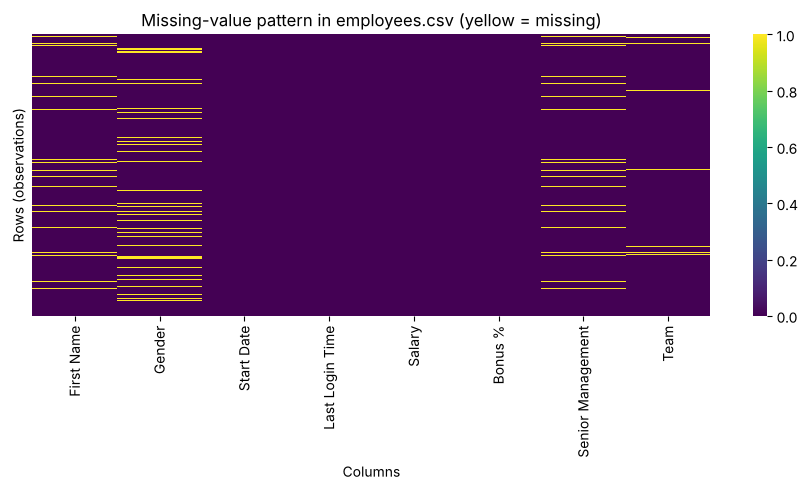

In [23]:
plt.figure(figsize=(9, 5))
sns.heatmap(emp.isna(), cbar=True, yticklabels=False, cmap="viridis")
plt.title("Missing-value pattern in employees.csv (yellow = missing)")
plt.xlabel("Columns"); plt.ylabel("Rows (observations)")
plt.tight_layout(); plt.show()

### 4. Copy + synthetic row (first name `'-'`, gender `'na'`, other fields missing)

In [24]:
emp_copy = emp.copy()
new_row = {
    "First Name": "-",            # placeholder, NOT recognised by pandas as missing
    "Gender": "na",               # placeholder, NOT recognised by pandas as missing
    "Start Date": np.nan,         # the other six fields get proper missing markers
    "Last Login Time": np.nan,
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": np.nan,
    "Team": np.nan,
}   # 8 fields, same structure as the dataset
emp_copy = pd.concat([emp_copy, pd.DataFrame([new_row])], ignore_index=True)
emp_copy.tail(3)

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
998,Larry,Male,4/20/2013,4:45 PM,60500.0,11.985,False,Business Development
999,Albert,Male,5/15/2012,6:24 PM,129949.0,10.169,True,Sales
1000,-,na,NaN,NaN,NaN,NaN,NaN,NaN


### 5. Recount the missing values

In [25]:
missing_after_row = emp_copy.isna().sum()
comparison = pd.DataFrame({"original": missing_before, "with synthetic row": missing_after_row})
comparison["difference"] = comparison["with synthetic row"] - comparison["original"]
comparison

,original,with synthetic row,difference
First Name,67,67,0
Gender,145,145,0
Start Date,0,1,1
Last Login Time,0,1,1
Salary,0,1,1
Bonus %,0,1,1
Senior Management,67,68,1
Team,43,44,1


**Why `'-'` and `'na'` are not counted.** `isna()` only detects the genuine missing-value objects (`NaN`/`None`/`NaT`/`pd.NA`). When reading a file, pandas also converts a fixed list of strings (`''`, `'NA'`, `'N/A'`, `'NaN'`, `'null'`, `'None'`…) to `NaN`, but `'-'` and lowercase `'na'` are not in that list, and a cell that was *added afterwards* in Python is just an ordinary string anyway. For pandas they are valid text values, so `First Name` and `Gender` show **no** increase, whereas the six genuine `NaN` fields do (+1 each). Placeholders must be converted explicitly.

### 6. Convert the markers to `np.nan` with a documented, case-insensitive rule

In [26]:
# RULE: in every text column, a value is a missing-value marker if, after removing
# surrounding spaces and lower-casing, it belongs to MARKERS. Such cells become np.nan.
MARKERS = {"-", "na", "n/a", "null", "none", ""}

def markers_to_nan(df, markers=MARKERS):
    out = df.copy()
    for col in out.columns:
        if not pd.api.types.is_numeric_dtype(out[col]):
            normalised = out[col].astype("string").str.strip().str.lower()
            out[col] = out[col].mask(normalised.isin(markers))   # marker -> NaN
    return out

emp_nan = markers_to_nan(emp_copy)
pd.DataFrame({"before conversion": emp_copy.isna().sum(), "after conversion": emp_nan.isna().sum()})

,before conversion,after conversion
First Name,67,68
Gender,145,146
Start Date,1,1
Last Login Time,1,1
Salary,1,1
Bonus %,1,1
Senior Management,68,68
Team,44,44


Now the synthetic row counts as missing in `First Name` (+1) and `Gender` (+1) too. The rule is case-insensitive (`'NA'`, `'Na'`, `'na'` are all treated alike) and its list of markers is explicit, which keeps it documented and reproducible. (A marker such as `'-'` should only be used if it can never be a legitimate value in that column.)

### 7. Imputation with `SimpleImputer` (fitted on the training data only)

In [27]:
from sklearn.impute import SimpleImputer

# Strategy per column:
num_cols = ["Salary", "Bonus %"]                          # numerical     -> median
cat_cols = ["Gender", "Senior Management", "Team"]        # categorical   -> most_frequent
# 'First Name' is an identifier-like column: no justified replacement value (filling it with
# the most frequent name would invent a person) -> left untouched.
# 'Start Date' and 'Last Login Time' have no missing values -> nothing to impute.

# Split BEFORE fitting the imputers (no target here: we just split the rows 80/20)
emp_train, emp_test = train_test_split(emp_nan, test_size=0.20, random_state=RANDOM_STATE)

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")
num_imputer.fit(emp_train[num_cols])           # statistics learned on TRAIN only
cat_imputer.fit(emp_train[cat_cols])

print("Medians learned on train:", dict(zip(num_cols, num_imputer.statistics_)))
print("Modes learned on train  :", dict(zip(cat_cols, cat_imputer.statistics_)))

def apply_imputers(df):
    out = df.copy()
    out[num_cols] = num_imputer.transform(df[num_cols])
    out[cat_cols] = cat_imputer.transform(df[cat_cols])
    return out

emp_train_imp = apply_imputers(emp_train)
emp_test_imp  = apply_imputers(emp_test)       # test data uses the statistics of the TRAIN set

Medians learned on train: {'Salary': np.float64(90556.0), 'Bonus %': np.float64(10.012)}
Modes learned on train  : {'Gender': 'Male', 'Senior Management': True, 'Team': 'Business Development'}


### 8. Missing values before / after preprocessing

In [28]:
emp_final = pd.concat([emp_train_imp, emp_test_imp]).sort_index()
report = pd.DataFrame({
    "original file":               emp.isna().sum(),
    "after adding row + markers":  emp_nan.isna().sum(),
    "after imputation":            emp_final.isna().sum()})
report

,original file,after adding row + markers,after imputation
First Name,67,68,68
Gender,145,146,0
Start Date,0,1,1
Last Login Time,0,1,1
Salary,0,1,0
Bonus %,0,1,0
Senior Management,67,68,0
Team,43,44,0


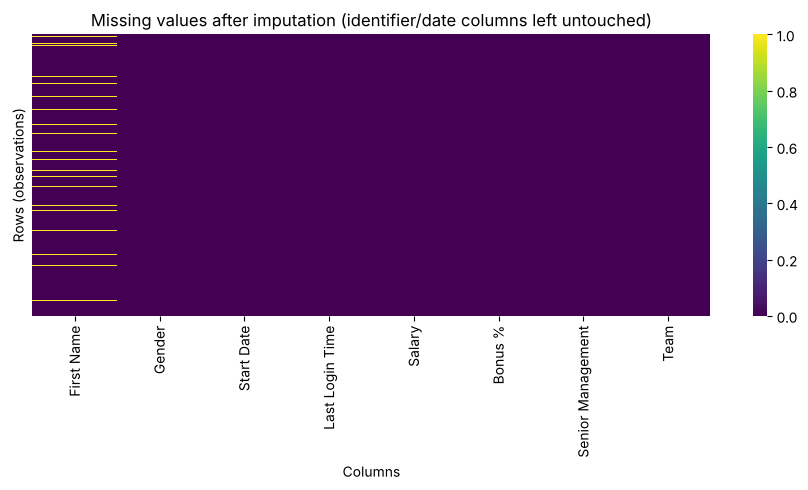

In [29]:
plt.figure(figsize=(9, 5))
sns.heatmap(emp_final.isna(), cbar=True, yticklabels=False, cmap="viridis")
plt.title("Missing values after imputation (identifier/date columns left untouched)")
plt.xlabel("Columns"); plt.ylabel("Rows (observations)"); plt.tight_layout(); plt.show()

**Result.** All imputed columns (`Salary`, `Bonus %`, `Gender`, `Senior Management`, `Team`) now have 0 missing values. Three columns still contain missing cells, on purpose: `First Name` (68 = 67 original + the placeholder of the synthetic row), because an identifier must not be invented, and `Start Date` / `Last Login Time` (1 each, both coming from the synthetic row only), because these columns had no missing values in the original file, so no imputation strategy was justified for them (such a row would normally be dropped or its dates handled separately).

**Limitations of imputation.**
- It **invents values**: the imputed number/category is an estimate, not an observation, and it can hide the fact that the information was missing (which may itself be informative, e.g. missing *Team* for some employees). A missing-indicator column can preserve that information.
- Median/mode imputation **reduces variance** and distorts distributions and correlations: the most frequent category (here the most frequent `Gender` or `Team`) becomes over-represented.
- It treats each column independently, ignoring relations with other variables (more advanced methods: `KNNImputer`, `IterativeImputer`, model-based).
- It assumes data missing completely at random; if the missingness depends on the value itself or other variables, the imputation is biased.
- Statistics must be learned on the **training set only** (as done above) and reused for validation/test data; otherwise information from the test set leaks into the model.

# Exercise 4 — Feature scaling, binarization and categorical encoding

## Part A — Scaling and binarization

In [30]:
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, MaxAbsScaler,
                                   RobustScaler, normalize, Binarizer)
X_num = np.array([[ 1, -1,  2],
                  [ 2,  0,  0],
                  [ 0,  1, -1]], dtype=float)
cols = ["Feature 1", "Feature 2", "Feature 3"]
show = lambda M: pd.DataFrame(M, columns=cols).round(3)
print("Original matrix:"); display(show(X_num))

Original matrix:


,Feature 1,Feature 2,Feature 3
0,1.0,-1.0,2.0
1,2.0,0.0,0.0
2,0.0,1.0,-1.0


### 1–2. Apply the five methods and display the results

In [31]:
results = {
    "StandardScaler": StandardScaler().fit_transform(X_num),     # per feature (column)
    "MinMaxScaler":   MinMaxScaler().fit_transform(X_num),       # per feature
    "MaxAbsScaler":   MaxAbsScaler().fit_transform(X_num),       # per feature
    "RobustScaler":   RobustScaler().fit_transform(X_num),       # per feature
    "normalize (L2)": normalize(X_num, norm="l2"),               # per sample (row) - a function
}
for name, M in results.items():
    print(name); display(show(M))

StandardScaler


,Feature 1,Feature 2,Feature 3
0,0.000,-1.225,1.336
1,1.225,0.000,-0.267
2,-1.225,1.225,-1.069


MinMaxScaler


,Feature 1,Feature 2,Feature 3
0,0.5,0.0,1.000
1,1.0,0.5,0.333
2,0.0,1.0,0.000


MaxAbsScaler


,Feature 1,Feature 2,Feature 3
0,0.5,-1.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,-0.5


RobustScaler


,Feature 1,Feature 2,Feature 3
0,0.0,-1.0,1.333
1,1.0,0.0,0.000
2,-1.0,1.0,-0.667


normalize (L2)


,Feature 1,Feature 2,Feature 3
0,0.408,-0.408,0.816
1,1.000,0.000,0.000
2,0.000,0.707,-0.707


In [32]:
print("Check column means / stds after StandardScaler:",
      results["StandardScaler"].mean(axis=0).round(3), results["StandardScaler"].std(axis=0).round(3))
print("Row norms after normalize:", np.linalg.norm(results["normalize (L2)"], axis=1).round(3))

Check column means / stds after StandardScaler: [0. 0. 0.] [1. 1. 1.]
Row norms after normalize: [1. 1. 1.]


### 3. Main idea of each method

| Method | Formula | Acts on | Result |
|---|---|---|---|
| `StandardScaler` | (x − mean) / std | **each feature** (column) | mean 0, variance 1 per feature (uses the population std) |
| `MinMaxScaler` | (x − min) / (max − min) | **each feature** | values in [0, 1] |
| `MaxAbsScaler` | x / max(\|x\|) | **each feature** | values in [−1, 1]; keeps zeros (sparse-friendly), no centring |
| `RobustScaler` | (x − median) / IQR | **each feature** | uses median and interquartile range, so it is robust to outliers |
| `normalize` | x / \|\|x\|\|₂ | **each sample** (row) | every row has unit norm; independent of other samples |

The first four are *scalers* (estimators with `fit`/`transform`, computing statistics per column on the training set); `normalize` is a stateless function that normalises each row to a unit norm (L2 by default), which changes the relative size of samples rather than the scale of features.

### 4. Binarization with an explicit threshold

In [33]:
for thr in (0.0, 1.0):
    B = Binarizer(threshold=thr).fit_transform(X_num)     # 1 if x > threshold else 0
    print(f"threshold = {thr}"); display(show(B))

threshold = 0.0


,Feature 1,Feature 2,Feature 3
0,1.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0


threshold = 1.0


,Feature 1,Feature 2,Feature 3
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,0.0


**Effect of the threshold.** `Binarizer` outputs 1 when the value is **strictly greater** than the threshold and 0 otherwise. With threshold 0, positive values become 1 (and the negative value −1 and zeros become 0); raising it to 1 keeps only the values above 1 (here only the 2s), so more entries become 0. The threshold therefore decides what counts as "present/active" and must be chosen from domain knowledge (it is not learned from the data).

**Discussion — why does scaling matter?**
- **k-NN and SVM (RBF/linear)** rely on distances or dot products. A feature with a large range (e.g. salary in thousands) dominates the distance and the other features become almost irrelevant; scaling puts the features on comparable scales.
- **Gradient-based models** (linear/logistic regression, neural networks): features with very different scales produce an ill-conditioned loss surface, so gradient descent converges slowly or unstably and regularisation penalises coefficients unevenly; scaling speeds up and stabilises the training.
- **Decision trees** (and ensembles of trees) are **not** sensitive to scaling: each split compares a single feature with a threshold, and any monotonic rescaling gives the same partitions. Scaling is therefore not necessary for them.

## Part B — Encoding categorical variables

In [34]:
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, OneHotEncoder
data = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target":    ["US", "France", "Japan", "Algeria"]})
data

,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria


### 1. `OrdinalEncoder` on the three input features

In [35]:
X_cat = data[["Feature 1", "Feature 2", "Feature 3"]]
ord_enc = OrdinalEncoder()
X_ord = ord_enc.fit_transform(X_cat)
print(pd.DataFrame(X_ord, columns=X_cat.columns).astype(int))
print()
for col, cats in zip(X_cat.columns, ord_enc.categories_):
    print(col, "->", {c: i for i, c in enumerate(cats)})
print("\ncategories_ :", ord_enc.categories_)

   Feature 1  Feature 2  Feature 3
0          1          3          2
1          0          2          2
2          0          1          1
3          1          0          0

Feature 1 -> {'female': 0, 'male': 1}
Feature 2 -> {'from Africa': 0, 'from Asia': 1, 'from Europe': 2, 'from US': 3}
Feature 3 -> {'uses Chrome': 0, 'uses Firefox': 1, 'uses Safari': 2}

categories_ : [array(['female', 'male'], dtype=object), array(['from Africa', 'from Asia', 'from Europe', 'from US'], dtype=object), array(['uses Chrome', 'uses Firefox', 'uses Safari'], dtype=object)]


The encoder sorts the categories of each column alphabetically and assigns them the integers 0, 1, 2… These numbers are only **category codes**: e.g. `from Asia = 1` and `from Europe = 2` do not mean that Europe is "greater than" Asia or that the distance Asia–Europe equals the distance Europe–US. No rank exists in these nominal variables.

### 2. Encode the target with `LabelEncoder`

In [36]:
y_cat = data["Target"]
label_enc = LabelEncoder()
y_num = label_enc.fit_transform(y_cat)
print("Encoded target:", y_num)
print("Mapping       :", {cls: int(i) for i, cls in enumerate(label_enc.classes_)})

Encoded target: [3 1 2 0]
Mapping       : {'Algeria': 0, 'France': 1, 'Japan': 2, 'US': 3}


### 3. `OneHotEncoder` on the target

In [37]:
onehot = OneHotEncoder(sparse_output=False)
y_onehot = onehot.fit_transform(y_cat.to_numpy().reshape(-1, 1))   # needs a 2-D array
print("Categories:", onehot.categories_[0])
pd.DataFrame(y_onehot.astype(int), columns=onehot.categories_[0], index=y_cat.values)

Categories: ['Algeria' 'France' 'Japan' 'US']


,Algeria,France,Japan,US
US,0,0,0,1
France,0,1,0,0
Japan,0,0,1,0
Algeria,1,0,0,0


**Integer label encoding vs one-hot encoding.** Label encoding represents each class by **one integer** in a single column (0 = Algeria, 1 = France, …). One-hot encoding creates **one binary column per category** with a single 1 per row. The integer code imposes an artificial order and distances between the classes, while the one-hot vectors are mutually orthogonal and equidistant: no class is "closer" to another. Label encoding is compact and accepted directly as target by scikit-learn classifiers; one-hot is used when a model needs a vector per class (e.g. a neural network with a softmax output).

### 4. Why one-hot encoding is preferable for nominal input features
Nominal variables (gender, country, browser…) have no natural order. With ordinal codes, a distance-based or linear model (k-NN, SVM, linear/logistic regression, neural networks) would interpret the integers as quantities: it would assume `Chrome (0) < Firefox (1) < Safari (2)`, that the average of Chrome and Safari is Firefox, and so on — relationships that do not exist and that bias the model. One-hot encoding gives each category its own independent binary feature, so no false order or distance is introduced. Its drawbacks are a larger number of columns (high-cardinality variables, sparse data) and the need to handle unseen categories (`handle_unknown="ignore"`). Tree-based models can cope with ordinal codes, and ordinal encoding is appropriate for variables that *do* have an order (e.g. small < medium < large).

# Conclusion — which preprocessing for which data type?

| Data type | Appropriate preprocessing |
|---|---|
| **Numerical** | Inspect with `describe()`; handle missing values (median, or mean if no outliers); **scale** (`StandardScaler`, `MinMaxScaler`, `RobustScaler` if outliers) for distance- or gradient-based models; `Binarizer` when only presence above a threshold matters; `normalize` to compare samples by direction. |
| **Categorical** | Convert placeholder markers (`'-'`, `'na'`…) to `NaN`; impute with the most frequent category (or a "missing" category); encode: **one-hot** for nominal variables, **ordinal** only for ordered ones, `LabelEncoder` for the target. Identifiers are not imputed. |
| **Text** | Read with the correct encoding, inspect (lengths, frequent words), clean (lower-casing, tokenisation); then convert to numeric vectors (bag-of-words / TF-IDF) before any model. |

General rules: always work on **copies**, check types and category values first, use a fixed `random_state`, and **fit every preprocessing step (imputers, scalers, encoders) on the training set only**, then apply it to validation/test data to avoid data leakage.